# Module B: stimulation planner (R0 / R1 controls, B1 heuristic, B2a templates, B2b learned planner)
Needs only the settings (it rebuilds the same layout as Module C). Writes the planner checkpoints to the `OUT` folder: `B2a_K*_s*.npy`, `B2b_<variant>_K*_s*.pt`, plus `T_c_s*.pt` (the helper classifier used in the task loss).

**Nothing repeats:** the shapes/contour data is generated once (`OUT/data_s*.npz`) and kept in memory; every classifier, template and planner is trained once and saved. Re-running a cell, or the whole notebook, loads checkpoints instead of training. To retrain on purpose set `RETRAIN_PLANNERS = True` (in the T_c cell) and run from there down.

Settings that change the data or the layout need a new `OUT` folder, which happens automatically (the name is built from them).

In [1]:
import os, sys, json, math, time, subprocess, urllib.parse, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw
import yaml, matplotlib.pyplot as plt
from scipy import ndimage
try: import dynaphos
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dynaphos"]); import dynaphos
from dynaphos.simulator import GaussianSimulator
from dynaphos.utils import Map
from dynaphos.cortex_models import get_cortex_coordinates_grid, get_visual_field_coordinates_from_cortex_full

# ---- keep-in-memory helper: an object is built once per kernel; re-running a cell re-uses it ----
_mem = globals().setdefault("_mem", {})
def once(name, key, build, verbose=True):
    if name in globals() and _mem.get(name) == key:
        if verbose: print(f"[memory] {name}: already loaded, nothing recomputed")
        return globals()[name]
    globals()[name] = build(); _mem[name] = key; return globals()[name]


In [2]:
# ======== shared settings: keep IDENTICAL in the notebooks for modules B, C and E ========
# (they find each other's files through the OUT folder, whose name is built from these values)
QUICK   = True        # True: small end-to-end run (minutes). False: full run (use a GPU)
SOURCE  = "shapes"    # "shapes" = circle/square/triangle/line (plan step A1) | "quickdraw" = stroke drawings
CLASSES = ["circle", "square", "triangle", "line"]    # quickdraw example: ["apple", "bed", "cup", "house", "key", "scissors"]
SIZE, RES, FOV = 256, 256, 10.0     # image size, Dynaphos render size, field of view in degrees
N_ELEC  = 500         # electrodes used (subsampled from a cortical grid inside the field)
I_MAX   = 200.0       # uA. MY CHOICE: brightness ~0.95 here with Dynaphos defaults. Verify against the safety literature.
SEED    = 0           # one seed per run; set 1, 2 and re-run for the other seeds (each seed is cached separately)
N_IMG   = dict(train=60, val=20, test=30) if QUICK else dict(train=400, val=80, test=100)   # drawings per class
dev = "cuda" if torch.cuda.is_available() else "cpu"
NC  = len(CLASSES)
OUT = f"pipeline_out_{'quick' if QUICK else 'full'}_{SOURCE}_{NC}c_{N_ELEC}e_{RES}"; os.makedirs(OUT, exist_ok=True)
KEY = (SEED, N_ELEC, SOURCE, tuple(CLASSES), QUICK, RES, FOV, I_MAX)      # anything cached in memory is rebuilt only if this changes
QD_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{}.ndjson"
print("device:", dev, "| outputs in", OUT)

# ======== experiment settings (modules B and E) ========
K_LIST = [5, 16, 32] if QUICK else [3, 5, 8, 12, 16, 24, 32, 48, 64]    # K grid for the accuracy-vs-K sweep
K_B2B  = [16] if QUICK else [8, 16, 32]                                  # K values for which the learned planners are trained
KB     = K_B2B[len(K_B2B) // 2]                                          # the K used for ablations / noise / probe
STEPS, BS, EPOCHS = (80, 8, 4) if QUICK else (600, 16, 15)               # B2b steps, batch size, classifier epochs
N_REP  = 2 if QUICK else 4                                               # random-dot samples per training image (T_c and E)
BOOT   = 500 if QUICK else 5000                                          # bootstrap resamples
VARIANTS = {"both": (1., .1, False), "contour_only": (1., 0., False), "task_only": (0., 1., False), "robust": (1., .1, True)}   # (lambda_contour, lambda_task, perturbation training)
def b2a_path(K): return f"{OUT}/B2a_K{K}_s{SEED}.npy"
def b2b_path(v, K): return f"{OUT}/B2b_{v}_K{K}_s{SEED}.pt"


device: cpu | outputs in pipeline_out_quick_shapes_4c_500e_256


In [3]:
# ---------------------------------------------------------------- Module C: frozen Dynaphos + electrode atlas
PARAMS_YAML = f"""
run: {{resolution: [{RES}, {RES}], view_angle: {FOV}, origin: [0, 0], min_angle: 0.001, fps: 35,
      gpu: {0 if torch.cuda.is_available() else 'null'}, print_stats: false, seed: 42, dtype: float32,
      use_gaussian_lut: false, batch_size: 0}}
display: {{screen_resolution: [1920, 1080], screen_diagonal: 13.3, dist_to_screen: 600}}
sampling: {{sampling_method: receptive_fields, RF_size: 0.5, stimulus_scale: 1.e-4}}
cortex_model: {{model: dipole, k: 17.3, a: 0.75, b: 120, alpha: 0.95, dropout_rate: 0.0, noise_scale: 0.4}}
temporal_dynamics: {{trace_increase_rate: 13.95528162, activation_decay_per_second: 0.00012340980408667956, trace_decay_per_second: 0.99949191}}
size: {{size_equation: sqrt, MD: 0.7, I_half: 40, slope_size: 0.08, current_spread: 675.e-6, radius_to_sigma: 0.5}}
brightness_saturation: {{cps_half: 1.057631326853325e-07, slope_brightness: 19152642.500946816}}
thresholding: {{use_threshold: true, rheobase: 23.9e-6, activation_threshold: 9.141886000943878e-08, activation_threshold_sd: 6.715877869833961e-08}}
default_stim: {{relative_stim_duration: 1, pw_default: 170.e-6, freq_default: 300}}
gabor: {{gabor_filtering: false, gamma: 1.5}}
"""   # = dynaphos config/params.yaml; changed: resolution, view_angle, dropout_rate 0 (dropout is applied at render time). Source: Dynaphos repo defaults.

class Phos:
    """Frozen Dynaphos + electrode atlas. render(I_uA) -> phosphene images; only active electrodes are summed (same maths as sim.__call__)."""
    def __init__(s, n_elec, seed):
        s.P = yaml.safe_load(PARAMS_YAML); rng = np.random.default_rng(seed)
        g = 32 if n_elec <= 1000 else 48
        cc = get_cortex_coordinates_grid(s.P["cortex_model"], g, g, x_max=40)       # g x g electrodes per hemisphere on the cortex
        x, y = get_visual_field_coordinates_from_cortex_full(s.P["cortex_model"], cc, rng).cartesian
        inb = (np.abs(x) < FOV / 2) & (np.abs(y) < FOV / 2)
        s.n_total, s.n_in_field = len(x), int(inb.sum())
        keep = rng.choice(np.flatnonzero(inb), min(n_elec, s.n_in_field), replace=False)
        s.sim = GaussianSimulator(s.P, Map(x=x[keep], y=y[keep]), rng)
        s.N, s.dev = s.sim.num_phosphenes, s.sim.data_kwargs["device"]
        co = s.sim.phosphene_maps.flatten(1).argmin(1).cpu().numpy()                 # pixel index of each phosphene centre
        s.xy = np.c_[x[keep], y[keep]]; s.px = np.c_[co % RES, co // RES]            # visual-field (deg) and pixel (col,row) centres
        p, dp, st = s.P["thresholding"], s.P["default_stim"], s.P["run"]["fps"]
        s.k_cur = st / (dp["pw_default"] * dp["freq_default"] * dp["relative_stim_duration"])   # activation -> current factor
        s.thr0 = s.sim.threshold.get().flatten()
        s.thr = ((p["rheobase"] + s.thr0.cpu().numpy() * s.k_cur) * 1e6 * 1.001 + 1e-3).astype(np.float32)   # uA, lowest current that shows a phosphene
        s.usable = s.thr <= I_MAX                                                    # electrodes that can ever be driven
        s.sim.reset(); s.sim.update(torch.full((s.N,), 128e-6, device=s.dev))        # size atlas at a reference current of 128 uA
        s.sigma_deg = s.sim.sigma.get().flatten().cpu().numpy(); s.sigma_px = s.sigma_deg / FOV * (RES - 1)
        s.ecc = np.linalg.norm(s.xy, axis=1)
        b = s.P["brightness_saturation"]; lvl = .7
        s.i70 = float((p["rheobase"] + (b["cps_half"] + math.log(lvl / (1 - lvl)) / b["slope_brightness"]) * s.k_cur) * 1e6)   # uA for 70 % brightness
        sg = torch.tensor(np.maximum(s.sigma_deg, 1.0 * FOV / (RES - 1)), device=s.dev)[:, None, None]
        W = torch.exp(-.5 * (s.sim.phosphene_maps / sg) ** 2).flatten(1); s.W = W / W.sum(1, keepdim=True)   # Gaussian sampling weights per electrode

    def render(s, I, p_drop=0., sigma_thr=0.):
        """I: (B,N) uA tensor (differentiable) -> (B,1,RES,RES). Optional electrode dropout and log-normal threshold jitter."""
        k = max(int((I > 0).sum(1).max()), 1); idx = I.topk(k, 1).indices; out = []
        for b in range(len(I)):
            if sigma_thr > 0: s.sim.threshold.state = (s.thr0 * torch.exp(sigma_thr * torch.randn_like(s.thr0))).view(-1, 1, 1)
            s.sim.reset(); s.sim.update(I[b].clamp_min(1e-3) * 1e-6)                 # clamp: sqrt(0) has an infinite gradient
            i = idx[b]; sg = s.sim.sigma.get().flatten()[i]; br = s.sim.brightness.get().flatten()[i]
            on = (s.sim.activation.get().flatten() > s.sim.threshold.get().flatten())[i].float() * (I[b][i] > 0).float()
            if p_drop > 0: on = on * (torch.rand(k, device=I.device) > p_drop).float()
            g = torch.exp(-.5 * (s.sim.phosphene_maps[i] / sg.clamp_min(1e-22)[:, None, None]) ** 2)
            out.append((on * br)[:, None, None].mul(g).sum(0))
        s.sim.threshold.state = s.thr0.view(-1, 1, 1)
        return torch.stack(out).clamp(0, 1)[:, None]

def save_atlas(C):
    np.savez(f"{OUT}/atlas_s{SEED}.npz", xy_deg=C.xy, px=C.px, sigma_deg=C.sigma_deg, thr_uA=C.thr, usable=C.usable, i70_uA=C.i70)

def check_atlas(C):
    f = f"{OUT}/atlas_s{SEED}.npz"
    if not os.path.exists(f): print("note: no atlas from the Module C notebook yet (run it once). The layout is rebuilt here from the same settings."); return
    a = np.load(f)
    assert a["xy_deg"].shape == C.xy.shape and np.allclose(a["xy_deg"], C.xy) and np.allclose(a["thr_uA"], C.thr, rtol=1e-3), \
        "this layout differs from the atlas written by the Module C notebook: settings or seed changed. Re-run Module C."
    print("layout matches the atlas written by the Module C notebook")


In [4]:
# ---------------------------------------------------------------- data: stroke drawings -> 256x256 images, contour targets (cached on disk)
def shape_strokes(c, rng):
    n = {"circle": 48, "square": 4, "triangle": 3, "line": 2}[c]
    a = np.linspace(0, 2 * np.pi, n, endpoint=False) + (np.pi / 4 if c == "square" else 0)
    p = np.c_[np.cos(a), np.sin(a) * (rng.uniform(.6, 1) if c != "line" else 0)]
    if c != "line": p = np.vstack([p, p[:1]])                       # close the outline
    t = rng.uniform(0, 2 * np.pi); p = p @ np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return [[list(p[:, 0]), list(p[:, 1])]]

def qd_strokes(name, n):
    f = f"{OUT}/qd_{name}.json"
    if os.path.exists(f) and len(json.load(open(f))) >= n: return json.load(open(f))[:n]
    req = urllib.request.Request(QD_URL.format(urllib.parse.quote(name)), headers={"Range": f"bytes=0-{3000 * n}"})
    raw = urllib.request.urlopen(req, timeout=60).read(3000 * n + 1).decode("utf-8", "ignore").split("\n")[:-1]   # last line may be cut
    out = [d["drawing"] for d in map(json.loads, raw) if d["recognized"]]
    if len(out) < n: raise RuntimeError(f"only {len(out)} drawings for {name}; raise the byte range")
    json.dump(out, open(f, "w")); return out[:n]

def draw(strokes, rng):
    pts = np.concatenate([np.c_[s[0], s[1]] for s in strokes]).astype(float)
    lo, hi = pts.min(0), pts.max(0); span = max((hi - lo).max(), 1e-6)
    ext = rng.uniform(.5, .95) * SIZE                                # object spans 50-95 % of the field
    ctr = SIZE / 2 + rng.uniform(-1, 1, 2) * (SIZE - ext) / 2        # position jitter
    im = Image.new("L", (SIZE, SIZE), 0); d = ImageDraw.Draw(im)
    for s in strokes:
        p = (np.c_[s[0], s[1]] - (lo + hi) / 2) * ext / span + ctr
        if len(p) > 1: d.line(list(map(tuple, p)), fill=255, width=3, joint="curve")
    return np.asarray(im)

def make_split(split, seed):
    off = {"train": 0, "val": N_IMG["train"], "test": N_IMG["train"] + N_IMG["val"]}[split]; n = N_IMG[split]
    X, y = [], []
    for ci, c in enumerate(CLASSES):
        qd = qd_strokes(c, sum(N_IMG.values())) if SOURCE == "quickdraw" else None
        for i in range(n):
            rng = np.random.default_rng([seed, off + i, ci])
            X.append(draw(qd[off + i] if qd else shape_strokes(c, rng), rng)); y.append(ci)
    return np.stack(X), np.array(y)

def gabor_bank(sig=2., lam=4., n=8, ks=15):
    r = torch.arange(ks, dtype=torch.float32) - ks // 2; yy, xx = torch.meshgrid(r, r, indexing="ij"); g = torch.exp(-(xx ** 2 + yy ** 2) / (2 * sig ** 2)); w = []
    for th in np.arange(n) * np.pi / n:
        ph = 2 * np.pi * (xx * np.cos(th) + yy * np.sin(th)) / lam
        ev = g * torch.cos(ph); ev = ev - g * ev.sum() / g.sum()                       # even part with the DC removed
        w += [ev, g * torch.sin(ph)]
    return torch.stack(w)[:, None].to(dev)                                            # (16,1,ks,ks): 8 orientations x (even, odd)

def blur(x, sig):
    r = int(3 * sig) + 1; k = torch.exp(-.5 * (torch.arange(-r, r + 1, device=x.device) / sig) ** 2); k = (k / k.sum()).to(x.dtype)
    return F.conv2d(F.conv2d(x, k.view(1, 1, 1, -1), padding=(0, r)), k.view(1, 1, -1, 1), padding=(r, 0))

def contour_map(x, GB):                                                               # x (B,1,256,256) -> C = sqrt(even^2 + odd^2), max over orientation
    r = F.conv2d(x, GB, padding=GB.shape[-1] // 2).view(len(x), 8, 2, SIZE, SIZE)
    c = r.pow(2).sum(2).sqrt().amax(1, keepdim=True); return c / c.amax((2, 3), keepdim=True).clamp_min(1e-6)

def prep_split(C, X, y, GB):
    """raw uint8 images (n,256,256) -> dict(x image, T blurred contour target, C contour map, score per electrode, y, X)."""
    o = {k: [] for k in ("x", "T", "C", "score")}; r = SIZE // RES
    for i in range(0, len(X), 16):
        x = torch.tensor(X[i:i + 16], dtype=torch.float32, device=dev)[:, None] / 255
        c = F.avg_pool2d(contour_map(x, GB), r); c = c / c.amax((2, 3), keepdim=True).clamp_min(1e-6)
        T = blur(c, 1.5); T = T / T.amax((2, 3), keepdim=True).clamp_min(1e-6)       # blurred contour target
        o["x"].append(F.avg_pool2d(x, r)); o["T"].append(T); o["C"].append(c[:, 0].cpu().numpy()); o["score"].append((c.flatten(1) @ C.W.T).cpu().numpy())
    D = {k: (np.concatenate(v) if k in ("C", "score") else torch.cat(v)) for k, v in o.items()}; D["y"] = y; D["X"] = X; return D

def get_data(C, GB, rebuild=False):
    """Builds the shapes + contour targets ONCE, saves them to OUT/data_s{SEED}.npz, and always loads from that file afterwards."""
    f = f"{OUT}/data_s{SEED}.npz"
    if rebuild or not os.path.exists(f):
        t0 = time.time(); z = {}
        for i, s in enumerate(("train", "val", "test")):
            D = prep_split(C, *make_split(s, 1000 * SEED + i), GB)
            z.update({f"{s}_X": D["X"], f"{s}_y": D["y"], f"{s}_T": D["T"].cpu().numpy().astype(np.float16),
                      f"{s}_C": D["C"].astype(np.float16), f"{s}_score": D["score"].astype(np.float32)})
        np.savez_compressed(f, **z); print(f"data: built and saved to {f} ({time.time() - t0:.0f}s)")
    z = np.load(f); D = {}
    for s in ("train", "val", "test"):
        X = z[f"{s}_X"]
        D[s] = dict(X=X, y=z[f"{s}_y"], x=F.avg_pool2d(torch.tensor(X, dtype=torch.float32, device=dev)[:, None] / 255, SIZE // RES),
                    T=torch.tensor(z[f"{s}_T"].astype(np.float32), device=dev), C=z[f"{s}_C"].astype(np.float32), score=z[f"{s}_score"])
    print(f"data: loaded from {f} | {NC} classes {CLASSES} | images per class train/val/test {N_IMG['train']}/{N_IMG['val']}/{N_IMG['test']}"); return D


In [5]:
# ---------------------------------------------------------------- reference arms, B1, planner network, constraints
def pick(xy, score, K, n0=120, r0=.15, floor=.1):
    """Greedy best-score selection with exclusion radius r0 (deg) and a 10 % floor, then homogeneous thinning to K (paper's density reduction)."""
    if score.max() <= 0: return np.array([], int)
    s = np.where(score >= floor * score.max(), score, -1.); ch = []
    while len(ch) < n0 and s.max() > 0:
        e = int(s.argmax()); ch.append(e); s[np.linalg.norm(xy - xy[e], axis=1) < r0] = -1
    ch = np.array(ch); Dm = np.linalg.norm(xy[ch][:, None] - xy[ch][None], axis=-1); alive = np.ones(len(ch), bool)
    while alive.sum() > K:
        i, j = np.unravel_index(np.where(alive[:, None] & alive[None] & ~np.eye(len(ch), dtype=bool), Dm, np.inf).argmin(), Dm.shape)
        alive[i if score[ch[i]] < score[ch[j]] else j] = False                        # drop the weaker of the closest pair
    return ch[alive]

def plan_b1(C, score, K):
    ch = pick(C.xy, score * C.usable, K); I = np.zeros(C.N, np.float32); I[ch] = np.clip(C.i70, C.thr[ch], I_MAX); return I

def plan_r1(C, K, rng):
    ch = rng.choice(np.flatnonzero(C.usable), K, replace=False); I = np.zeros(C.N, np.float32); I[ch] = rng.uniform(C.thr[ch], I_MAX); return I

def dots(pts, sig=1.5, amp=.9):                                                       # pts (K,2) pixel (col,row) -> Gaussian dot image (idealised scoreboard)
    g = np.arange(RES); d2 = (g[None, :, None] - pts[:, 0, None, None]) ** 2 + (g[None, None, :] - pts[:, 1, None, None]) ** 2
    return np.exp(-.5 * d2 / sig ** 2).sum(0).clip(0, 1).T * amp if len(pts) else np.zeros((RES, RES))

def plan_r0(Cmap, K, rng, thin=True):
    ys, xs = np.nonzero(Cmap > .2); sel = rng.choice(len(xs), min(600, len(xs)), replace=False)
    pts = np.c_[xs[sel], ys[sel]].astype(float); sc = Cmap[ys[sel], xs[sel]]
    ch = pick(pts * FOV / (RES - 1), sc, K) if thin else rng.choice(len(pts), min(K, len(pts)), replace=False)
    return dots(pts[ch])

def topk_st(logits, K):                                                               # hard top-K forward, sigmoid gradient backward
    soft = torch.sigmoid(logits); hard = torch.zeros_like(soft).scatter_(1, logits.topk(K, 1).indices, 1.)
    return hard + soft - soft.detach()

def currents(C, logits, u, K):                                                        # I = m * (thr + (I_max - thr) * sigmoid(u)), always in [thr, I_max]
    thr = torch.tensor(C.thr, device=dev); lg = logits.masked_fill(~torch.tensor(C.usable, device=dev), -1e4)
    return topk_st(lg, K) * (thr + (I_MAX - thr) * torch.sigmoid(u))

class Planner(nn.Module):
    """B2b: small CNN encoder -> features sampled at each electrode's phosphene centre -> shared MLP -> (selection logit, amplitude logit)."""
    def __init__(s, C):
        super().__init__()
        cv = lambda i, o, d: nn.Sequential(nn.Conv2d(i, o, 3, padding=d, dilation=d), nn.ReLU())
        s.enc = nn.Sequential(cv(1, 16, 1), cv(16, 16, 2), cv(16, 16, 4), cv(16, 16, 8), nn.Conv2d(16, 16, 1))
        s.mlp = nn.Sequential(nn.Linear(18, 64), nn.ReLU(), nn.Linear(64, 2))
        s.register_buffer("grid", torch.tensor(C.px / (RES - 1) * 2 - 1, dtype=torch.float32)[None, :, None])
        s.register_buffer("geo", torch.tensor(np.c_[C.sigma_px / 2, C.ecc / FOV], dtype=torch.float32)[None])
    def forward(s, x):
        f = F.grid_sample(s.enc(x), s.grid.expand(len(x), -1, -1, -1), align_corners=True)[..., 0].transpose(1, 2)
        h = s.mlp(torch.cat([f, s.geo.expand(len(x), -1, -1)], -1)); return h[..., 0], h[..., 1]

def run_arm(arm, C, D, K, rng, M, noise=(0., 0.), variant="both"):
    """arm in R0 | R1 | B1 | B2a | B2b -> (phosphene images (n,1,RES,RES), currents or None). M holds the trained B2 models."""
    n = len(D["y"])
    if arm == "R0": return torch.tensor(np.stack([plan_r0(D["C"][b], K, rng) for b in range(n)]), device=dev, dtype=torch.float32)[:, None], None
    if arm == "R1": I = np.stack([plan_r1(C, K, rng) for _ in range(n)])
    elif arm == "B1": I = np.stack([plan_b1(C, D["score"][b], K) for b in range(n)])
    elif arm == "B2a": I = M["tmpl"][K][D["y"]]
    else:
        with torch.no_grad(): I = currents(C, *M["b2b"][(variant, K)](D["x"]), K).cpu().numpy()
    with torch.no_grad(): P = torch.cat([C.render(torch.tensor(I[i:i + 16], device=dev), *noise) for i in range(0, n, 16)])
    return P, I

def fidelity(P, T, tau=2):
    """precision / recall / F-score of phosphene mass versus the contour, tolerance tau px (about one phosphene radius)."""
    Tn = T / T.amax((2, 3), keepdim=True).clamp_min(1e-6); Mk = (Tn > .5).float(); Dl = (F.max_pool2d(Mk, 2 * tau + 1, 1, tau) > 0).float()
    prec = ((P * Dl).sum((1, 2, 3)) / (P.sum((1, 2, 3)) + 1e-6)).cpu().numpy()
    rec = ((Mk * (F.max_pool2d((P > .05).float(), 2 * tau + 1, 1, tau))).sum((1, 2, 3)) / (Mk.sum((1, 2, 3)) + 1e-6)).cpu().numpy()
    return prec, rec, 2 * prec * rec / (prec + rec + 1e-9)

def visible(P): return np.array([ndimage.label(p[0].cpu().numpy() > .05)[1] for p in P])   # distinct phosphene blobs above a brightness criterion
def to_u8(P): return (P.clamp(0, 1) * 255).round().to(torch.uint8)


In [6]:
# ---------------------------------------------------------------- classifiers on sparse-dot images (T_c in module B, E in module E)
def make_cnn():                                                                       # T_c: plain CNN (training classifier used inside B2b's task loss)
    blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(1, 16), blk(16, 32), blk(32, 64), blk(64, 64), blk(64, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, NC))

class Res(nn.Module):
    def __init__(s, i, o, st):
        super().__init__(); s.a = nn.Sequential(nn.Conv2d(i, o, 3, st, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o))
        s.sc = nn.Sequential() if (i == o and st == 1) else nn.Sequential(nn.Conv2d(i, o, 1, st, bias=False), nn.BatchNorm2d(o))
    def forward(s, x): return F.relu(s.a(x) + s.sc(x))

def make_resnet():                                                                    # E: ResNet-style evaluator, different family from A and T_c
    return nn.Sequential(nn.Conv2d(1, 16, 3, 2, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), Res(16, 16, 1), Res(16, 32, 2), Res(32, 64, 2), Res(64, 64, 2),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, NC))

def front(P): return blur(P, 1.2) * 4                                                 # fixed front-end for both classifiers: dots -> small blobs

def fit_clf(net, X, y, seed, path, retrain=False):
    """Trains net on uint8 dot images X (n,1,H,W). If `path` exists the saved weights are loaded and NOTHING is trained."""
    if os.path.exists(path) and not retrain: net.load_state_dict(torch.load(path, map_location=dev)); print(f"loaded {path} (no training)"); return net.eval()
    t0 = time.time(); torch.manual_seed(seed); opt = torch.optim.Adam(net.parameters(), 2e-3); n = len(y); yt = torch.tensor(y, device=dev)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=EPOCHS * ((n + 63) // 64))
    for ep in range(EPOCHS):
        net.train(); perm = torch.randperm(n, device=dev)
        for i in range(0, n, 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(net(front(X[b].float() / 255)), yt[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        print(f"  epoch {ep + 1}/{EPOCHS} loss {loss.item():.3f}")
    torch.save(net.state_dict(), path); print(f"trained and saved {path} ({time.time() - t0:.0f}s)"); return net.eval()

@torch.no_grad()
def clf_acc(net, X, y, bs=64):
    p = torch.cat([net(front(X[i:i + bs].float() / 255)).argmax(1).cpu() for i in range(0, len(X), bs)]); return (p.numpy() == y).astype(float)

def dot_data(C, D, mode, seed):
    """Classifier training data independent of every planner: 'board' = random dots on the true contour; 'elec' = Dynaphos renders of random contour-adjacent electrodes."""
    rng = np.random.default_rng(seed); X, y = [], []; n = len(D["y"])
    for rep in range(N_REP):
        ims = []
        for b in range(n):
            K = int(rng.integers(3, 65))
            if mode == "board":
                ys, xs = np.nonzero(D["C"][b] > .3); sel = rng.choice(len(xs), min(K, len(xs)), replace=False)
                pts = np.c_[xs[sel], ys[sel]] + rng.normal(0, 1, (len(sel), 2)); pts = pts[rng.random(len(pts)) > rng.uniform(0, .3)]
                ims.append(dots(pts, rng.uniform(1, 2.5), rng.uniform(.6, 1)))
            else:
                sc = D["score"][b] * C.usable; cand = np.flatnonzero(sc > .2 * sc.max()); sel = rng.choice(cand, min(K, len(cand)), replace=False)
                I = np.zeros(C.N, np.float32); I[sel] = rng.uniform(C.thr[sel], I_MAX); ims.append(I)
        if mode == "board": P = np.stack(ims)
        else:
            with torch.no_grad(): P = torch.cat([C.render(torch.tensor(np.stack(ims[i:i + 16]), device=dev), rng.choice([0, .1, .2]), rng.choice([0, .1, .25])) for i in range(0, n, 16)])[:, 0].cpu().numpy()
        X.append((P * 255).astype(np.uint8)); y.append(D["y"])
    return np.concatenate(X), np.concatenate(y)

def get_dots(C, D, mode, split, seed):
    """dot_data with an on-disk cache: generated once, loaded from OUT/dots_*.npz on every later run."""
    f = f"{OUT}/dots_{mode}_{split}_{seed}.npz"
    if not os.path.exists(f):
        t0 = time.time(); X, y = dot_data(C, D, mode, seed); np.savez_compressed(f, X=X, y=y); print(f"dots {mode}/{split}: generated and saved ({time.time() - t0:.0f}s)")
    z = np.load(f); return torch.tensor(z["X"], device=dev)[:, None], z["y"]


In [7]:
# ---------------------------------------------------------------- B2: loss, templates, training
def contour_loss(P, T, tau=2):
    """(1 - cosine of blurred images) [scale-free MSE] + (1 - precision) + (1 - recall); precision/recall use tolerance tau px."""
    Tn = T / T.amax((2, 3), keepdim=True).clamp_min(1e-6); Pb, Tb = blur(P, 1.5).flatten(1), blur(Tn, 1.5).flatten(1)
    cos = (Pb * Tb).sum(1) / (Pb.norm(dim=1) * Tb.norm(dim=1) + 1e-6)
    Dl = (F.max_pool2d(Tn, 2 * tau + 1, 1, tau) > .3).float(); Mk = (Tn > .5).float()
    prec = (P * Dl).sum((1, 2, 3)) / (P.sum((1, 2, 3)) + 1e-6)
    cov = 1 - torch.exp(-blur(P, tau) * 2 * math.pi * tau ** 2)
    rec = (Mk * cov).sum((1, 2, 3)) / (Mk.sum((1, 2, 3)) + 1e-6)
    return ((1 - cos) + (1 - prec) + (1 - rec)).mean()

def train_b2(C, Dtr, Dva, Tc, K, lam_c, lam_t, robust, seed, variant, retrain=False):
    """B2b amortised planner. If its checkpoint exists it is loaded and NOTHING is trained."""
    f = b2b_path(variant, K); net = Planner(C).to(dev)
    if os.path.exists(f) and not retrain: net.load_state_dict(torch.load(f, map_location=dev)); print(f"  B2b[{variant}] K={K}: loaded {f} (no training)"); return net.eval()
    t0 = time.time(); torch.manual_seed(seed); rng = np.random.default_rng(seed); opt = torch.optim.Adam(net.parameters(), 1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS); yt = torch.tensor(Dtr["y"], device=dev); best = (1e9, None)
    nz = (float(rng.choice([.05, .1, .2])), .25) if robust else (0., 0.)
    for it in range(STEPS):
        net.train(); b = torch.tensor(rng.integers(0, len(yt), BS), device=dev); lg, u = net(Dtr["x"][b]); I = currents(C, lg, u, K)
        P = C.render(I, *nz); loss = lam_c * contour_loss(P, Dtr["T"][b])
        lt = lam_t * min(1., max(0., (it / STEPS - .4) / .2))                          # task loss ramps in late
        if lt > 0: loss = loss + lt * F.cross_entropy(Tc(front(P)), yt[b])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if (it + 1) % max(STEPS // 5, 1) == 0:                                         # model selection on validation CONTOUR loss only
            net.eval()
            with torch.no_grad(): v = contour_loss(C.render(currents(C, *net(Dva["x"][:16]), K)), Dva["T"][:16]).item()
            print(f"  B2b[{variant}] K={K} step {it + 1}/{STEPS}  train loss {loss.item():.3f}  val contour loss {v:.3f}")
            if v < best[0]: best = (v, {k: t.clone() for k, t in net.state_dict().items()})
    net.load_state_dict(best[1]); torch.save(net.state_dict(), f); print(f"  saved {f} ({time.time() - t0:.0f}s)"); return net.eval()

def train_templates(C, Dtr, K, steps=100, retrain=False):
    """B2a: one optimised current vector per class, fitted to that class's mean contour target (ignores where the object actually is)."""
    f = b2a_path(K)
    if os.path.exists(f) and not retrain: print(f"  B2a K={K}: loaded {f} (no training)"); return np.load(f)
    I_all = []
    for c in range(NC):
        m = Dtr["y"] == c; T = Dtr["T"][torch.tensor(m, device=dev)].mean(0, keepdim=True); T = T / T.max()
        z = torch.tensor((Dtr["score"][m].mean(0) * C.usable), device=dev, dtype=torch.float32); z = ((z - z.mean()) / (z.std() + 1e-6))[None]
        lg = z.clone().requires_grad_(True); u = torch.zeros(1, C.N, device=dev, requires_grad=True); opt = torch.optim.Adam([lg, u], .1)
        for _ in range(steps):
            loss = contour_loss(C.render(currents(C, lg, u, K)), T); opt.zero_grad(); loss.backward(); opt.step()
        I_all.append(currents(C, lg, u, K).detach().cpu().numpy()[0])
    I_all = np.stack(I_all); np.save(f, I_all); print(f"  B2a K={K}: trained and saved {f}"); return I_all


### Layout (kept in memory) and data (cached on disk + in memory)

In [8]:
C = once("C", KEY, lambda: Phos(N_ELEC, SEED)); check_atlas(C); print(f"{C.N} electrodes, {C.usable.sum()} usable")
GB = once("GB", KEY, gabor_bank, verbose=False)
REBUILD_DATA = False                           # True = regenerate the shapes/contours once (resets itself)
if REBUILD_DATA: _mem.pop("D", None)
D = once("D", KEY, lambda: get_data(C, GB, REBUILD_DATA)); REBUILD_DATA = False
Dtr, Dva, Dte = D["train"], D["val"], D["test"]; print({k: len(v["y"]) for k, v in D.items()}, "images")


layout matches the atlas written by the Module C notebook
500 electrodes, 498 usable
data: built and saved to pipeline_out_quick_shapes_4c_500e_256/data_s0.npz (12s)
data: loaded from pipeline_out_quick_shapes_4c_500e_256/data_s0.npz | 4 classes ['circle', 'square', 'triangle', 'line'] | images per class train/val/test 60/20/30
{'train': 240, 'val': 80, 'test': 120} images


### Reference arms and B1 (no training)

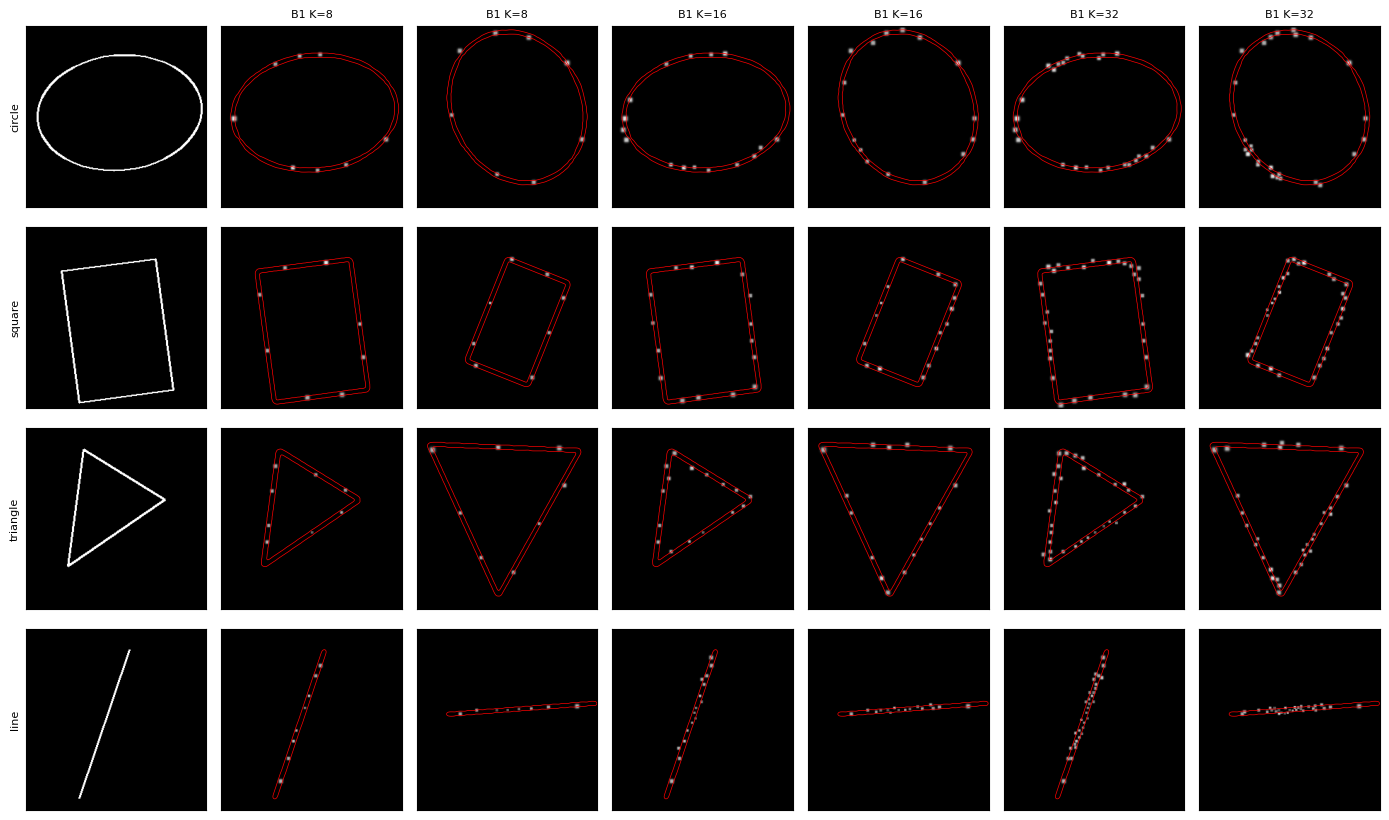

contour fidelity on the test set (precision / recall / F) and phosphene counts. R0 = ideal dots, R1 = random electrodes, B1 = heuristic
  R0 K= 8  precision 1.00  recall 0.25  F 0.38  visible   8.0
  R0 K=16  precision 1.00  recall 0.47  F 0.61  visible  15.7
  R0 K=32  precision 0.99  recall 0.75  F 0.84  visible  26.1
  R1 K= 8  precision 0.09  recall 0.01  F 0.02  visible   7.9  active 8.0
  R1 K=16  precision 0.08  recall 0.02  F 0.03  visible  15.7  active 16.0
  R1 K=32  precision 0.08  recall 0.05  F 0.05  visible  31.1  active 32.0
  B1 K= 8  precision 0.96  recall 0.17  F 0.29  visible   8.0  active 8.0
  B1 K=16  precision 0.93  recall 0.30  F 0.45  visible  15.9  active 16.0
  B1 K=32  precision 0.90  recall 0.44  F 0.59  visible  28.9  active 30.5


In [9]:
# ---------- B1 heuristic + R0 / R1 reference arms: look at them, check coverage grows with K ----------
rng = np.random.default_rng(0); M0 = {"tmpl": {}, "b2b": {}}                  # no learned models needed for these arms
fig, ax = plt.subplots(NC, 7, figsize=(14, 2.1 * NC), squeeze=False); Ks = [k for k in (8, 16, 32)]
for j in range(NC):
    i0 = int(np.flatnonzero(Dte["y"] == j)[0]); ax[j, 0].imshow(Dte["x"][i0, 0].cpu(), cmap="gray"); ax[j, 0].set_ylabel(CLASSES[j], fontsize=8)
    for col, K in enumerate(Ks):
        for sub, i in enumerate((i0, int(np.flatnonzero(Dte["y"] == j)[1]))):
            Di = {k: (v[i:i + 1] if not isinstance(v, torch.Tensor) else v[i:i + 1]) for k, v in Dte.items()}
            P, I = run_arm("B1", C, Di, K, rng, M0); ax[j, 1 + 2 * col + sub].imshow(F.max_pool2d(P, 3, 1, 1)[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            ax[j, 1 + 2 * col + sub].contour(Di["T"][0, 0].cpu(), [.5], colors="r", linewidths=.5)
            if j == 0: ax[j, 1 + 2 * col + sub].set_title(f"B1 K={K}", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print("contour fidelity on the test set (precision / recall / F) and phosphene counts. R0 = ideal dots, R1 = random electrodes, B1 = heuristic")
for arm in ("R0", "R1", "B1"):
    for K in (8, 16, 32):
        P, I = run_arm(arm, C, Dte, K, np.random.default_rng(0), M0); pr, rc, f = fidelity(P, Dte["T"])
        print(f"  {arm} K={K:2d}  precision {pr.mean():.2f}  recall {rc.mean():.2f}  F {f.mean():.2f}  visible {visible(P).mean():5.1f}" + (f"  active {(I > 0).sum(1).mean():.1f}" if I is not None else ""))


### T_c, the helper classifier for the task loss (trained once)

In [10]:
# ---------- T_c: the helper (training) classifier used inside B2b's task loss. Trained on random-dot images only; saved once. ----------
RETRAIN_PLANNERS = False        # True = retrain T_c, the templates and ALL planners below (resets itself to False afterwards)
def build_tc():
    Xb, yb = get_dots(C, Dtr, "board", "train", 500 + SEED)       # its own dot samples, never shown to E
    net = fit_clf(make_cnn().to(dev), Xb, yb, 7 + SEED, f"{OUT}/T_c_s{SEED}.pt", RETRAIN_PLANNERS)
    for p in net.parameters(): p.requires_grad_(False)
    return net
if RETRAIN_PLANNERS: _mem.pop("Tc", None)
Tc = once("Tc", KEY, build_tc)
Xv, yv = get_dots(C, Dva, "board", "val", 300 + SEED); print(f"T_c accuracy on held-out random-dot images: {clf_acc(Tc, Xv, yv).mean():.1%}")


dots board/train: generated and saved (49s)
  epoch 1/4 loss 1.339
  epoch 2/4 loss 1.290
  epoch 3/4 loss 1.192
  epoch 4/4 loss 1.157
trained and saved pipeline_out_quick_shapes_4c_500e_256/T_c_s0.pt (102s)
dots board/val: generated and saved (18s)
T_c accuracy on held-out random-dot images: 39.4%


### B2a templates and B2b planners (trained once each, then loaded from disk)

In [11]:
# ---------- B2a templates + B2b planners. Each is trained ONCE and its checkpoint saved in OUT; re-running loads them (no retraining). ----------
def build_models():
    M = {"tmpl": {K: train_templates(C, Dtr, K, retrain=RETRAIN_PLANNERS) for K in K_B2B}, "b2b": {}}
    for v, (lc, lt, rb) in VARIANTS.items():
        for K in (K_B2B if v == "both" else [KB]):
            M["b2b"][(v, K)] = train_b2(C, Dtr, Dva, Tc, K, lc, lt, rb, SEED, v, RETRAIN_PLANNERS)
    return M
if RETRAIN_PLANNERS: _mem.pop("M", None)
t0 = time.time(); M = once("M", KEY, build_models); RETRAIN_PLANNERS = False
print(f"planners ready ({time.time() - t0:.0f}s): templates K={sorted(M['tmpl'])}, B2b {sorted(M['b2b'])}")


  B2a K=16: trained and saved pipeline_out_quick_shapes_4c_500e_256/B2a_K16_s0.npy
  B2b[both] K=16 step 16/80  train loss 1.558  val contour loss 1.578
  B2b[both] K=16 step 32/80  train loss 1.491  val contour loss 1.554
  B2b[both] K=16 step 48/80  train loss 1.762  val contour loss 1.588
  B2b[both] K=16 step 64/80  train loss 1.706  val contour loss 1.586
  B2b[both] K=16 step 80/80  train loss 1.670  val contour loss 1.586
  saved pipeline_out_quick_shapes_4c_500e_256/B2b_both_K16_s0.pt (141s)
  B2b[contour_only] K=16 step 16/80  train loss 2.990  val contour loss 2.998
  B2b[contour_only] K=16 step 32/80  train loss 2.997  val contour loss 2.998
  B2b[contour_only] K=16 step 48/80  train loss 2.894  val contour loss 2.986
  B2b[contour_only] K=16 step 64/80  train loss 2.909  val contour loss 2.895
  B2b[contour_only] K=16 step 80/80  train loss 2.740  val contour loss 2.753
  saved pipeline_out_quick_shapes_4c_500e_256/B2b_contour_only_K16_s0.pt (118s)
  B2b[task_only] K=16 ste

### Side-by-side check

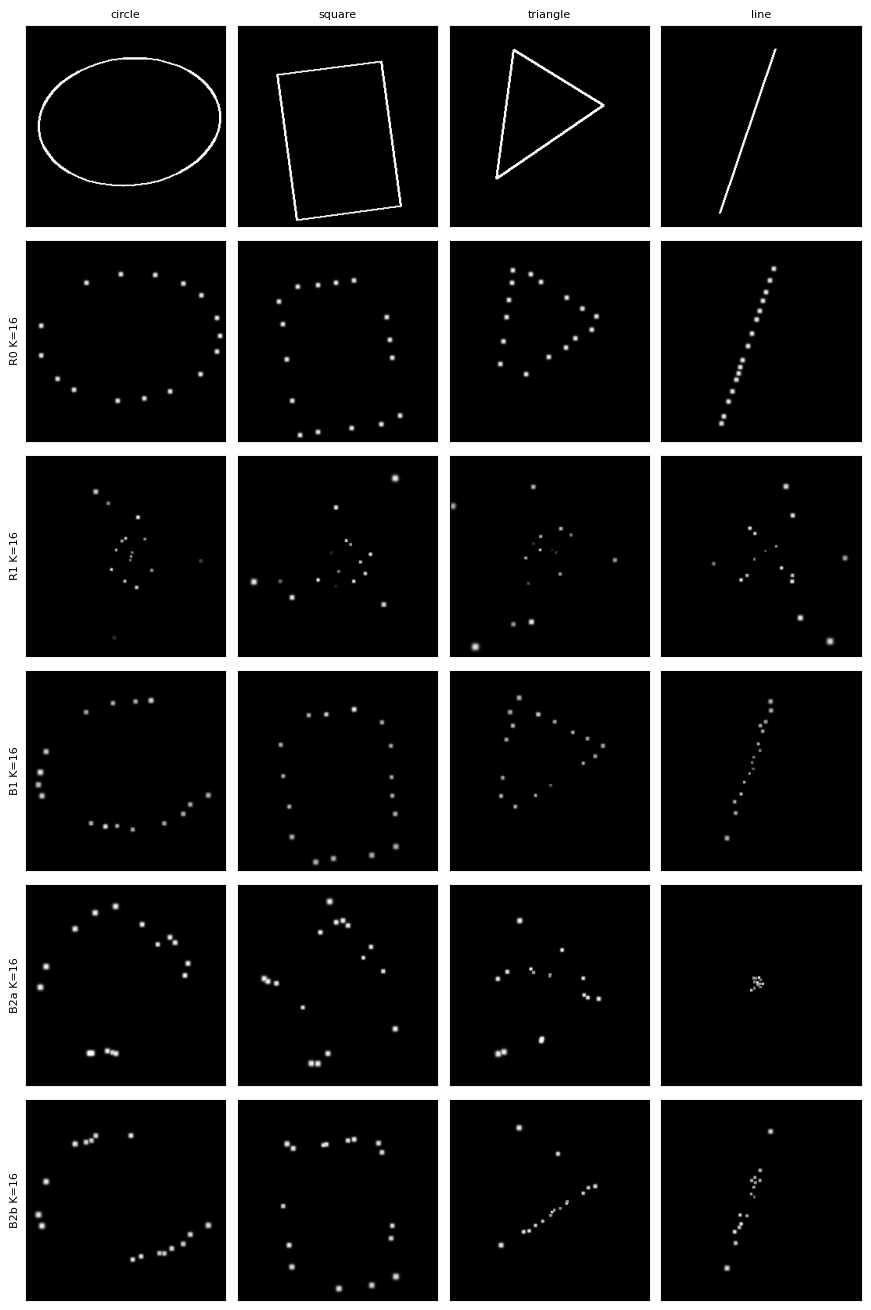

  K=16 R0  precision 1.00  recall 0.47  F 0.61
  K=16 R1  precision 0.08  recall 0.02  F 0.03
  K=16 B1  precision 0.93  recall 0.30  F 0.45
  K=16 B2a precision 0.18  recall 0.04  F 0.06
  K=16 B2b precision 0.93  recall 0.25  F 0.39

Module B is done. Module E loads the saved planners from pipeline_out_quick_shapes_4c_500e_256


In [12]:
# ---------- quick look: all five arms side by side, and contour fidelity (not the evaluator: that is Module E) ----------
rng = np.random.default_rng(0); arms = ["R0", "R1", "B1", "B2a", "B2b"]
for K in K_B2B:
    ids = [int(np.flatnonzero(Dte["y"] == c)[0]) for c in range(NC)]; Dm = {k: (v[ids] if not isinstance(v, torch.Tensor) else v[torch.tensor(ids, device=v.device)]) for k, v in Dte.items()}
    fig, ax = plt.subplots(len(arms) + 1, NC, figsize=(2.2 * NC, 2.2 * (len(arms) + 1)), squeeze=False)
    for j in range(NC): ax[0, j].imshow(Dm["x"][j, 0].cpu(), cmap="gray"); ax[0, j].set_title(CLASSES[j], fontsize=8)
    for i, a in enumerate(arms):
        P, _ = run_arm(a, C, Dm, K, rng, M)
        for j in range(NC): ax[i + 1, j].imshow(F.max_pool2d(P, 3, 1, 1)[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)    # 3x3 dilation for display only
        ax[i + 1, 0].set_ylabel(f"{a} K={K}", fontsize=8)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(f"{OUT}/examples_K{K}_s{SEED}.png", dpi=110); plt.show()
    for a in arms:
        P, I = run_arm(a, C, Dte, K, np.random.default_rng(0), M); pr, rc, f = fidelity(P, Dte["T"])
        print(f"  K={K:2d} {a:3s} precision {pr.mean():.2f}  recall {rc.mean():.2f}  F {f.mean():.2f}")
print("\nModule B is done. Module E loads the saved planners from", OUT)
